# 03 · Regression models (Unit III)

Full training run: `python -m src.regression` (7 models, raw and log target, GridSearchCV + TimeSeriesSplit). This notebook loads its saved results and adds two small live experiments.

In [1]:
# Make the project folder importable (notebooks live in notebooks/)
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from config import project_config as cfg
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
val = pd.read_csv(cfg.METRICS_DIR / 'regression_validation_results.csv')
val.sort_values('val_RMSE')

,model,target,best_params,cv_RMSE,train_RMSE,train_R2,val_MAE,val_MSE,val_RMSE,val_R2
10,Lasso,log(cnt+1),"{""alpha"": 0.001}",85.61,52.92,0.8917,47.55,5541.3,74.44,0.8962
12,Elastic Net,log(cnt+1),"{""alpha"": 0.001, ""l1_ratio"": 0.2}",85.25,52.60,0.8930,47.65,5679.6,75.36,0.8936
8,Ridge,log(cnt+1),"{""alpha"": 0.1}",85.42,52.36,0.8939,50.16,6553.5,80.95,0.8772
6,Polynomial,log(cnt+1),"{""poly_degree"": 2}",85.43,52.37,0.8939,50.20,6566.6,81.03,0.8770
4,Multiple Linear,log(cnt+1),{},94.55,60.92,0.8564,65.89,11984.6,109.47,0.7755
5,Polynomial,cnt,"{""poly_degree"": 2}",87.11,63.35,0.8447,84.09,12125.7,110.12,0.7729
7,Ridge,cnt,"{""alpha"": 0.1}",87.15,63.35,0.8447,84.10,12128.3,110.13,0.7728
9,Lasso,cnt,"{""alpha"": 0.001}",86.71,63.36,0.8447,84.11,12131.4,110.14,0.7728
11,Elastic Net,cnt,"{""alpha"": 0.001, ""l1_ratio"": 0.8}",87.41,63.41,0.8444,84.45,12233.2,110.60,0.7708
3,Multiple Linear,cnt,{},87.34,64.59,0.8386,87.05,12947.8,113.79,0.7575


In [3]:
test = pd.read_csv(cfg.METRICS_DIR / 'regression_test_results.csv')
test.sort_values('test_RMSE')

,model,target,selected_on_validation,test_MAE,test_MSE,test_RMSE,test_R2
8,Ridge,log(cnt+1),False,40.72,4415.7,66.45,0.8913
6,Polynomial,log(cnt+1),False,40.72,4416.6,66.46,0.8913
12,Elastic Net,log(cnt+1),False,41.56,4455.6,66.75,0.8904
10,Lasso,log(cnt+1),True,42.49,4585.6,67.72,0.8872
4,Multiple Linear,log(cnt+1),False,43.04,4955.2,70.39,0.8781
3,Multiple Linear,cnt,False,68.63,8991.7,94.82,0.7787
7,Ridge,cnt,False,70.66,9219.1,96.02,0.7731
5,Polynomial,cnt,False,70.68,9222.1,96.03,0.7731
9,Lasso,cnt,False,70.68,9222.5,96.03,0.7731
11,Elastic Net,cnt,False,70.85,9244.5,96.15,0.7725


In [4]:
import json
json.load(open(cfg.MODELS_DIR / 'regression_model_meta.json'))

{'task': 'regression',
 'target': 'cnt',
 'selected_model': 'Lasso',
 'target_transform': 'log(cnt+1)',
 'best_params': {'alpha': 0.001},
 'selection_rule': 'lowest validation RMSE (Jul-Sep 2012); tuned with 5-fold TimeSeriesSplit on train',
 'validation_metrics': {'MAE': 47.55,
  'MSE': 5541.3,
  'RMSE': 74.44,
  'R2': 0.8962},
 'test_metrics': {'MAE': 42.49, 'MSE': 4585.6, 'RMSE': 67.72, 'R2': 0.8872},
 'final_fit': 'train + validation (2011-01-01 to 2012-09-30)',
 'features': ['temp',
  'hum',
  'windspeed',
  'season',
  'mnth',
  'hr',
  'weekday',
  'weathersit',
  'hr_workingday',
  'yr',
  'holiday',
  'workingday'],
 'random_seed': 42,
 'versions': {'python': '3.13.15',
  'scikit-learn': '1.9.1',
  'pandas': '3.1.0',
  'numpy': '2.5.4'}}

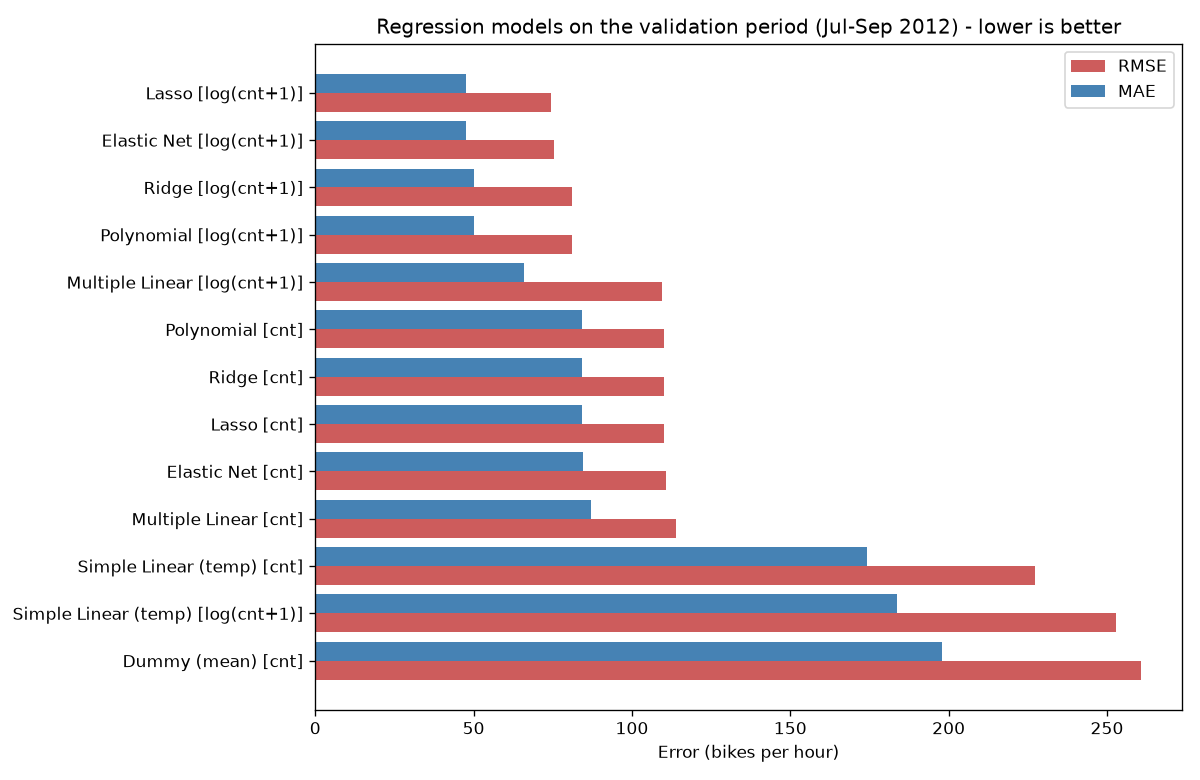

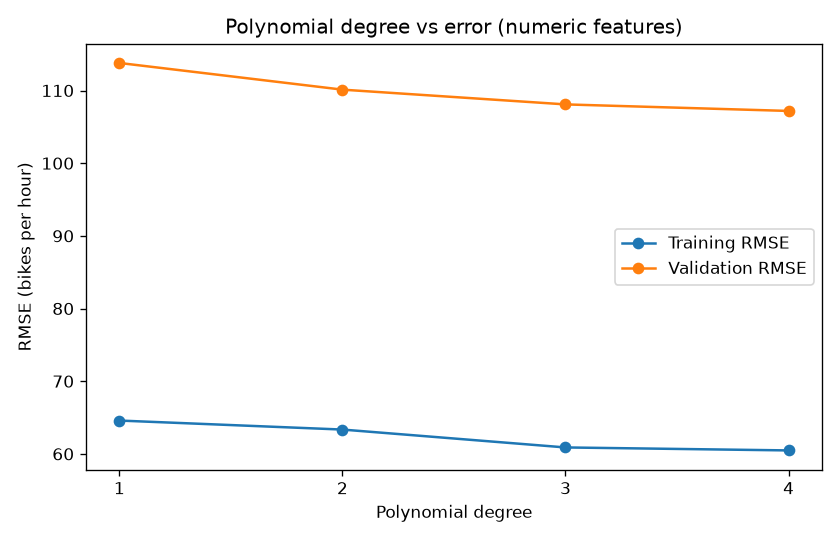

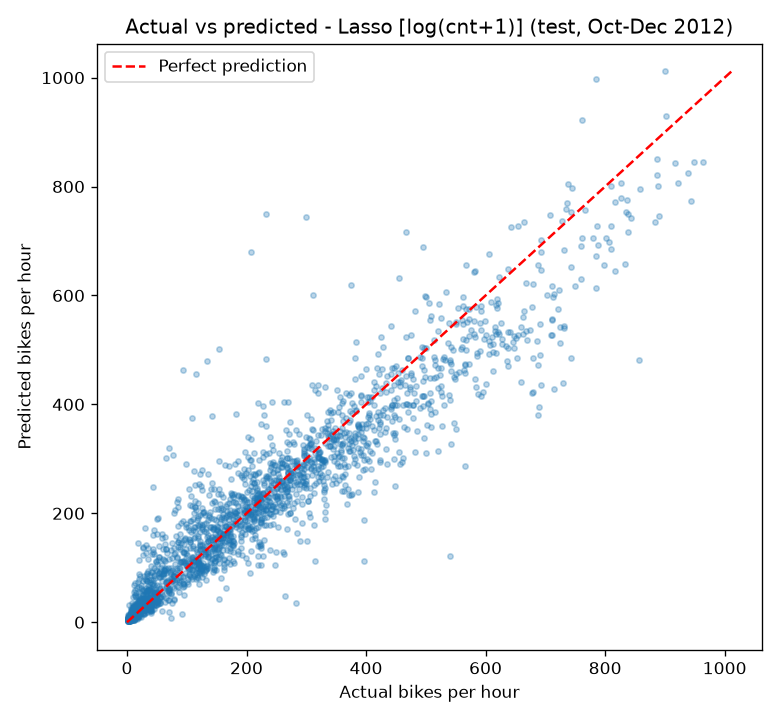

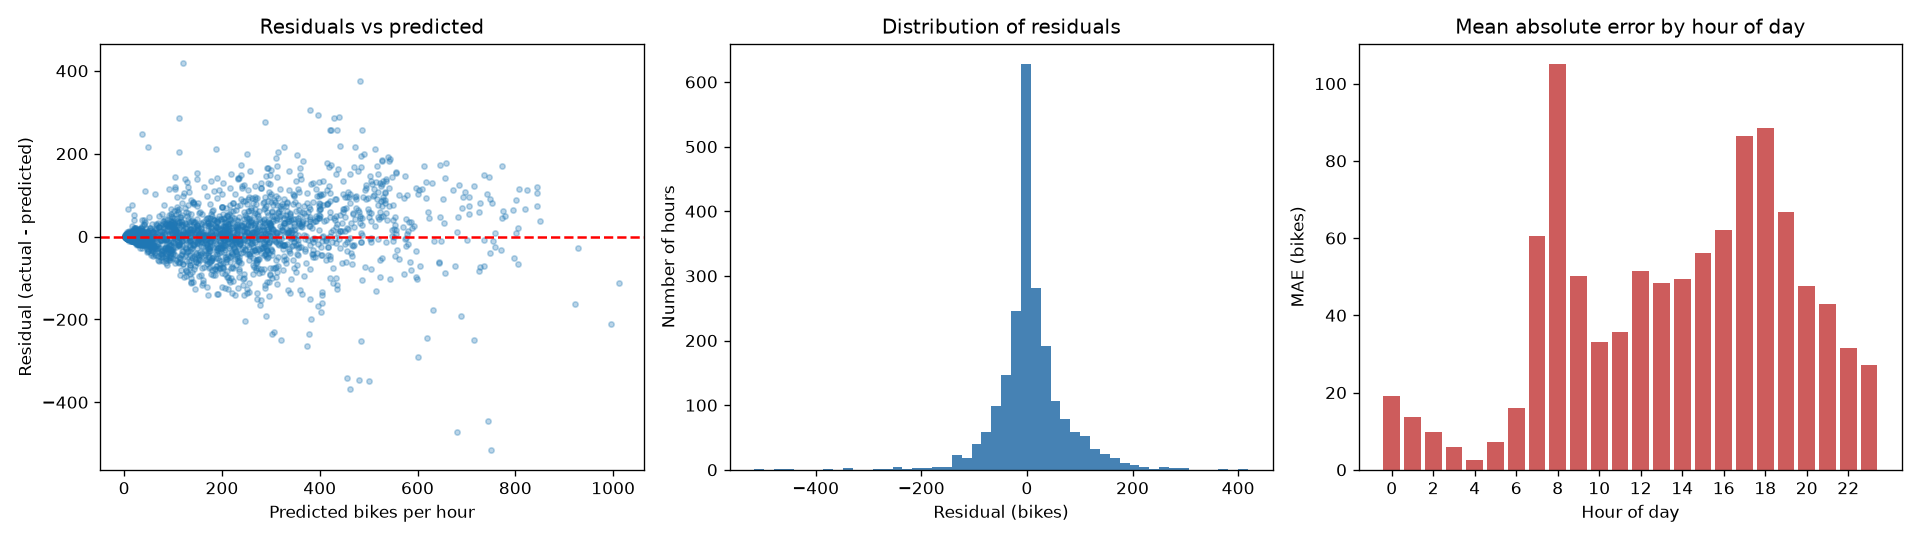

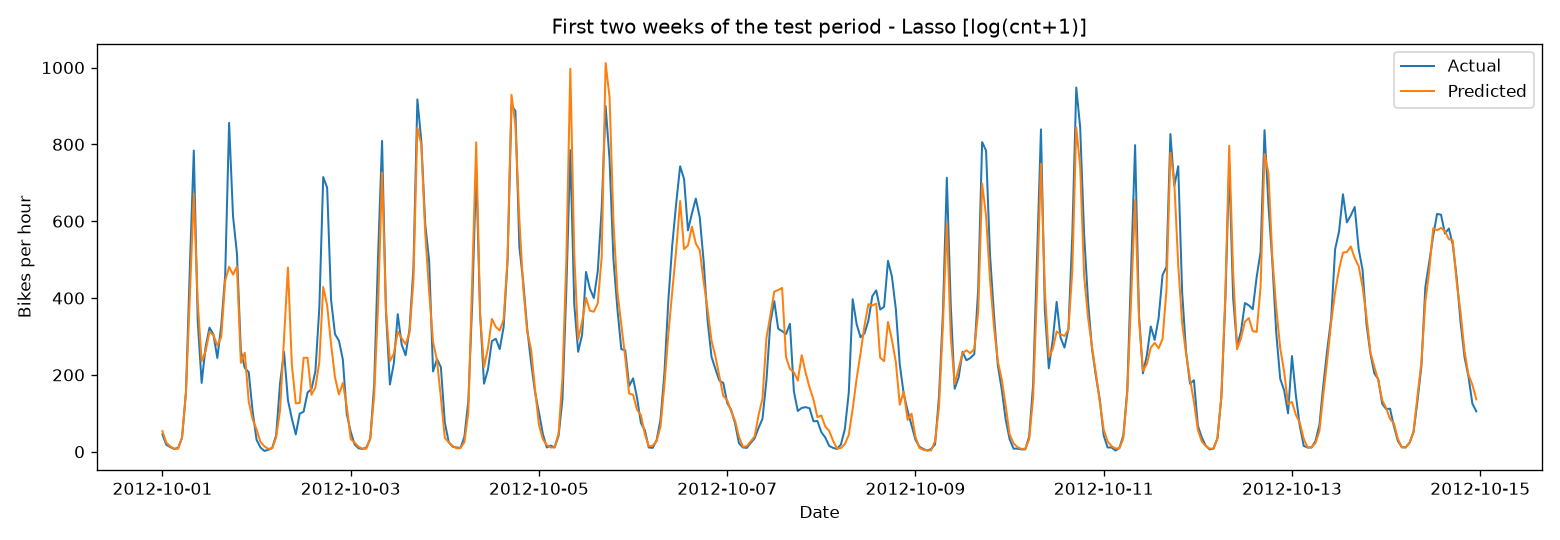

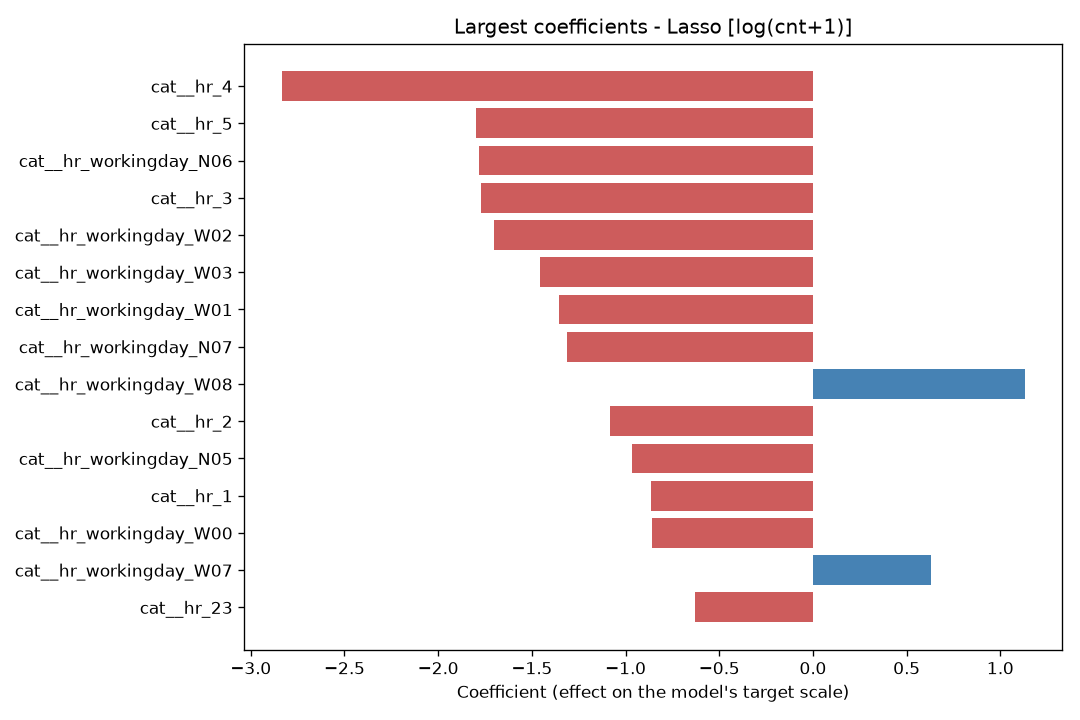

In [5]:
for name in ['09_regression_validation_comparison', '10_polynomial_degree_curve', '11_regression_actual_vs_predicted', '12_regression_residuals', '13_regression_test_two_weeks', '14_regression_top_coefficients']:
    display(Image(filename=str(cfg.FIGURES_DIR / f'{name}.png')))

## Live experiment 1: Simple Linear Regression
One input (temperature). The coefficient says how many extra bikes per hour the model expects for each extra °C.

In [6]:
from sklearn.linear_model import LinearRegression
from src.data_loader import load_hour_data
from src.feature_engineering import add_features
from src.preprocessing import chronological_split
from src.evaluation import regression_metrics
tr, va, te = chronological_split(add_features(load_hour_data()))
to_c = lambda s: s * (cfg.TEMP_MAX_C - cfg.TEMP_MIN_C) + cfg.TEMP_MIN_C
lr = LinearRegression().fit(to_c(tr[['temp']]), tr['cnt'])
print(f'cnt = {lr.intercept_:.1f} + {lr.coef_[0]:.2f} x temperature(°C)')
print('validation:', regression_metrics(va['cnt'], lr.predict(to_c(va[['temp']]))))

cnt = 58.6 + 7.45 x temperature(°C)
validation: {'MAE': 174.29, 'MSE': 51681.4, 'RMSE': 227.34, 'R2': 0.0319}


## Live experiment 2: effect of the Ridge penalty (alpha)
Larger alpha shrinks coefficients more. Too large → underfitting (both errors rise).

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from src.preprocessing import build_preprocessor
from src.feature_engineering import ALL_FEATURES
rows = []
for a in [0.01, 1, 100, 1000, 10000]:
    p = Pipeline([('prep', build_preprocessor('poly')), ('model', Ridge(alpha=a))]).fit(tr[ALL_FEATURES], tr['cnt'])
    rows.append({'alpha': a, 'train_RMSE': regression_metrics(tr['cnt'], p.predict(tr[ALL_FEATURES]))['RMSE'],
                 'val_RMSE': regression_metrics(va['cnt'], p.predict(va[ALL_FEATURES]))['RMSE']})
pd.DataFrame(rows)

,alpha,train_RMSE,val_RMSE
0,0.01,66.49,110.11
1,1.00,66.49,110.29
2,100.00,69.64,124.87
3,1000.00,97.75,171.63
4,10000.00,131.88,219.07
